# RQ4: Combined Dimensionality Reduction (PCA) and Classification

This notebook combines the PCA dimensionality reduction from RQ3 with the classification models from RQ4. To ensure rigorous evaluation and prevent data leakage, **ComBat harmonization, Standardization, and PCA are applied strictly inside the cross-validation folds**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, balanced_accuracy_score

# pip install neuroCombat
from neuroCombat import neuroCombat, neuroCombatFromTraining

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
RNG = 42
np.random.seed(RNG)

print('Setup complete.')

Setup complete.


## 1. Data Loading and Preparation

In [2]:
# Load datasets
df_clean = pd.read_csv('../dataset/abide_solution_A.csv')
df_pheno = pd.read_csv('../Phenotypic_V1_0b_preprocessed1.csv')

# Cortical thickness columns (68 regions: 34 lh + 34 rh)
THICKNESS_COLS = sorted([c for c in df_clean.columns if c.startswith(('lh_', 'rh_'))])

# Ensure metadata columns are present
for col in ['SITE_ID', 'AGE_AT_SCAN', 'SEX', 'DX_GROUP']:
    if col not in df_clean.columns:
        df_clean = df_clean.merge(df_pheno[['SUB_ID', col]], on='SUB_ID', how='left')

# Drop subjects with missing values
df_clean = df_clean.dropna(subset=THICKNESS_COLS + ['SITE_ID', 'AGE_AT_SCAN', 'SEX', 'DX_GROUP']).reset_index(drop=True)

# Re-encode diagnosis: 1 = ASD, 0 = Control
y_all = (df_clean['DX_GROUP'] == 1).astype(int)
X_all = df_clean[THICKNESS_COLS].copy()
sites_all = df_clean['SITE_ID'].astype(str).copy()
age_all = df_clean['AGE_AT_SCAN'].copy()
sex_all = df_clean['SEX'].astype(str).copy()

print(f'Total subjects: {len(df_clean)}')
print(f'ASD (1): {(y_all == 1).sum()} | Control (0): {(y_all == 0).sum()}')

Total subjects: 1027
ASD (1): 499 | Control (0): 528


### Stratified Train/Test Split
We seal a 20% hold-out test set.

In [3]:
# Hold-out split — stratified by diagnosis
idx = np.arange(len(df_clean))
idx_tr, idx_te = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=RNG)

def take(s, idx_): return s.iloc[idx_].reset_index(drop=True)

X_train, X_test = take(X_all, idx_tr), take(X_all, idx_te)
y_train, y_test = take(y_all, idx_tr), take(y_all, idx_te)
sites_train, sites_test = take(sites_all, idx_tr), take(sites_all, idx_te)
age_train, age_test = take(age_all, idx_tr), take(age_all, idx_te)
sex_train, sex_test = take(sex_all, idx_tr), take(sex_all, idx_te)

print(f'Train N = {len(X_train)} | Test N = {len(X_test)}')

Train N = 821 | Test N = 206


## 2. Leakage-Free CV Pipeline with PCA
Here we define custom helper functions that fit ComBat and PCA strictly on the training fold, and apply them to the validation fold.

In [4]:
def fit_combat_train(X_train_df, sites_train, age_train, sex_train):
    data_T = X_train_df.T.values
    covars = pd.DataFrame({
        'SITE_ID': sites_train.reset_index(drop=True).astype(str).values,
        'AGE':     age_train.reset_index(drop=True).values,
        'SEX':     sex_train.reset_index(drop=True).astype(str).values,
    })
    result = neuroCombat(
        dat=data_T, covars=covars, batch_col='SITE_ID',
        categorical_cols=['SEX'], continuous_cols=['AGE']
    )
    X_harm = pd.DataFrame(result['data'].T, columns=X_train_df.columns, index=X_train_df.index)
    return X_harm, result['estimates']

def apply_combat_test(X_test_df, sites_test, estimates):
    data_T = X_test_df.T.values
    result = neuroCombatFromTraining(
        dat=data_T, batch=sites_test.reset_index(drop=True).astype(str).values, estimates=estimates
    )
    X_harm = pd.DataFrame(result['data'].T, columns=X_test_df.columns, index=X_test_df.index)
    return X_harm

def compute_metrics(y_true, y_pred, y_proba=None):
    m = {
        'accuracy':    accuracy_score(y_true, y_pred),
        'sensitivity': recall_score(y_true, y_pred, pos_label=1),
        'specificity': recall_score(y_true, y_pred, pos_label=0),
        'f1':          f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }
    if y_proba is not None: m['auc_roc'] = roc_auc_score(y_true, y_proba)
    return m

In [5]:
def evaluate_pipeline(classifier, params, X, y, sites, age, sex, n_components=19, n_splits=5):
    '''Evaluates a classifier using a rigorous ComBat -> Scaler -> PCA in-fold pipeline'''
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RNG)
    fold_metrics = []
    
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
        s_tr, s_va = sites.iloc[tr_idx], sites.iloc[va_idx]
        a_tr, a_va = age.iloc[tr_idx], age.iloc[va_idx]
        x_tr, x_va = sex.iloc[tr_idx], sex.iloc[va_idx]

        # ComBat
        X_tr_h, est = fit_combat_train(X_tr, s_tr, a_tr, x_tr)
        X_va_h = apply_combat_test(X_va, s_va, est)

        # Scaler
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr_h)
        X_va_s = scaler.transform(X_va_h)
        
        # PCA (from RQ3, optimal k=19)
        pca = PCA(n_components=n_components, random_state=RNG)
        X_tr_pca = pca.fit_transform(X_tr_s)
        X_va_pca = pca.transform(X_va_s)

        # Classifier
        clf = clone(classifier).set_params(**params)
        clf.fit(X_tr_pca, y_tr)
        
        y_pred = clf.predict(X_va_pca)
        y_proba = clf.predict_proba(X_va_pca)[:, 1] if hasattr(clf, 'predict_proba') else None
        
        m = compute_metrics(y_va, y_pred, y_proba)
        fold_metrics.append(m)
        
    return pd.DataFrame(fold_metrics).mean()

## 3. Model Training & Cross Validation (GridSearch)

In [6]:
from itertools import product
def manual_grid_search(classifier_class, param_grid, n_components=19):
    keys = list(param_grid.keys())
    combos = list(product(*[param_grid[k] for k in keys]))
    best_score = -1
    best_params = None
    best_metrics = None
    
    for combo in combos:
        params = dict(zip(keys, combo))
        metrics = evaluate_pipeline(classifier_class(), params, X_train, y_train, sites_train, age_train, sex_train, n_components)
        if metrics['auc_roc'] > best_score:
            best_score = metrics['auc_roc']
            best_params = params
            best_metrics = metrics
            
    return best_params, best_metrics

results_cv = {}
best_models = {}

In [7]:
# 1. SVM (RBF and Linear)
svm_grid = {'kernel': ['rbf', 'linear'], 'C': [0.1, 1.0, 10.0], 'probability': [True], 'random_state': [RNG]}
print("Tuning SVM...")
best_svm_params, best_svm_metrics = manual_grid_search(SVC, svm_grid)
results_cv['SVM (PCA)'] = best_svm_metrics
best_models['SVM'] = SVC(**best_svm_params)
print(f"Best SVM Params: {best_svm_params}\nCV AUC: {best_svm_metrics['auc_roc']:.3f}")

Tuning SVM...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[ne

In [8]:
# 2. CART
cart_grid = {'max_depth': [3, 5, 7, None], 'min_samples_split': [2, 5, 10], 'random_state': [RNG]}
print("\nTuning CART...")
best_cart_params, best_cart_metrics = manual_grid_search(DecisionTreeClassifier, cart_grid)
results_cv['CART (PCA)'] = best_cart_metrics
best_models['CART'] = DecisionTreeClassifier(**best_cart_params)
print(f"Best CART Params: {best_cart_params}\nCV AUC: {best_cart_metrics['auc_roc']:.3f}")


Tuning CART...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[

In [9]:
# 3. KNN
knn_grid = {'n_neighbors': [3, 5, 9, 15, 21], 'weights': ['uniform', 'distance']}
print("\nTuning KNN...")
best_knn_params, best_knn_metrics = manual_grid_search(KNeighborsClassifier, knn_grid)
results_cv['KNN (PCA)'] = best_knn_metrics
best_models['KNN'] = KNeighborsClassifier(**best_knn_params)
print(f"Best KNN Params: {best_knn_params}\nCV AUC: {best_knn_metrics['auc_roc']:.3f}")


Tuning KNN...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[n

In [10]:
# 4. Naive Bayes
nb_grid = {'var_smoothing': np.logspace(-9, -1, 5)}
print("\nTuning Naive Bayes...")
best_nb_params, best_nb_metrics = manual_grid_search(GaussianNB, nb_grid)
results_cv['Naive Bayes (PCA)'] = best_nb_metrics
best_models['NB'] = GaussianNB(**best_nb_params)
print(f"Best NB Params: {best_nb_params}\nCV AUC: {best_nb_metrics['auc_roc']:.3f}")


Tuning Naive Bayes...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjust

## 4. Final Hold-Out Evaluation
Now we take our best models, train them on the *full* training set, and evaluate them strictly on the test set.

In [11]:
# Final rigorous preprocessing on full train/test sets
# 1. ComBat
X_train_h, est_full = fit_combat_train(X_train, sites_train, age_train, sex_train)
X_test_h = apply_combat_test(X_test, sites_test, est_full)

# 2. StandardScaler
scaler_full = StandardScaler()
X_train_hs = scaler_full.fit_transform(X_train_h)
X_test_hs = scaler_full.transform(X_test_h)

# 3. PCA (k=19)
pca_full = PCA(n_components=19, random_state=RNG)
X_train_pca = pca_full.fit_transform(X_train_hs)
X_test_pca = pca_full.transform(X_test_hs)

# Create Soft Voting Ensemble
best_models['Voting Ensemble'] = VotingClassifier(
    estimators=[(name, clf) for name, clf in best_models.items() if name != 'Voting Ensemble'],
    voting='soft'
)

# Fit all and evaluate
final_test_results = {}
final_test_proba = {}

for name, clf in best_models.items():
    clf.fit(X_train_pca, y_train)
    y_pred = clf.predict(X_test_pca)
    y_proba = clf.predict_proba(X_test_pca)[:, 1] if hasattr(clf, 'predict_proba') else None
    
    final_test_results[name] = compute_metrics(y_test, y_pred, y_proba)
    final_test_proba[name] = y_proba

final_df = pd.DataFrame(final_test_results).T
print("=== FINAL TEST RESULTS (ComBat -> Scaler -> PCA -> Classifier) ===")
display(final_df.round(3).sort_values('auc_roc', ascending=False))

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

=== FINAL TEST RESULTS (ComBat -> Scaler -> PCA -> Classifier) ===


,accuracy,sensitivity,specificity,f1,auc_roc
Voting Ensemble,0.558,0.50,0.613,0.524,0.579
NB,0.602,0.51,0.689,0.554,0.578
CART,0.563,0.52,0.604,0.536,0.575
SVM,0.510,0.42,0.594,0.454,0.527
KNN,0.519,0.23,0.792,0.317,0.502


## 5. Visualizations

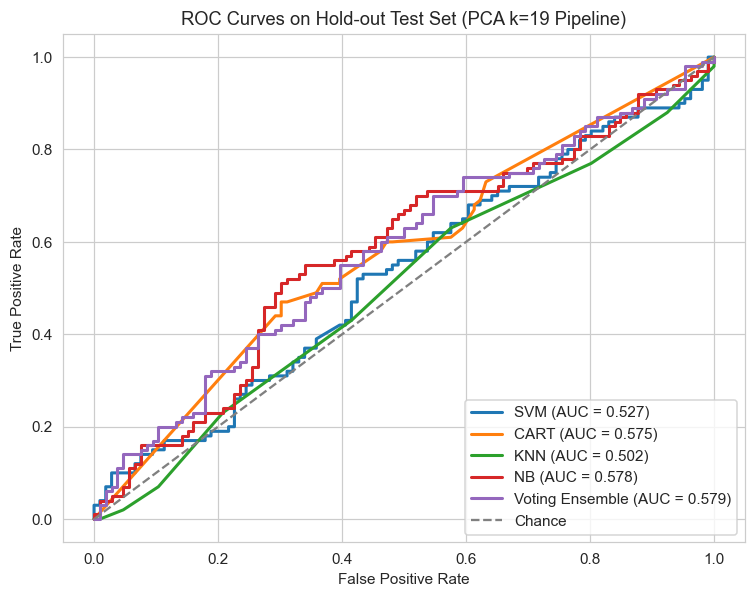

In [12]:
# ROC Curves
fig, ax = plt.subplots(figsize=(8, 6))
for name, proba in final_test_proba.items():
    if proba is not None:
        fpr, tpr, _ = roc_curve(y_test, proba)
        auc_val = roc_auc_score(y_test, proba)
        ax.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_val:.3f})')

ax.plot([0, 1], [0, 1], '--', color='grey', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves on Hold-out Test Set (PCA k=19 Pipeline)')
ax.legend(loc='lower right')
plt.show()

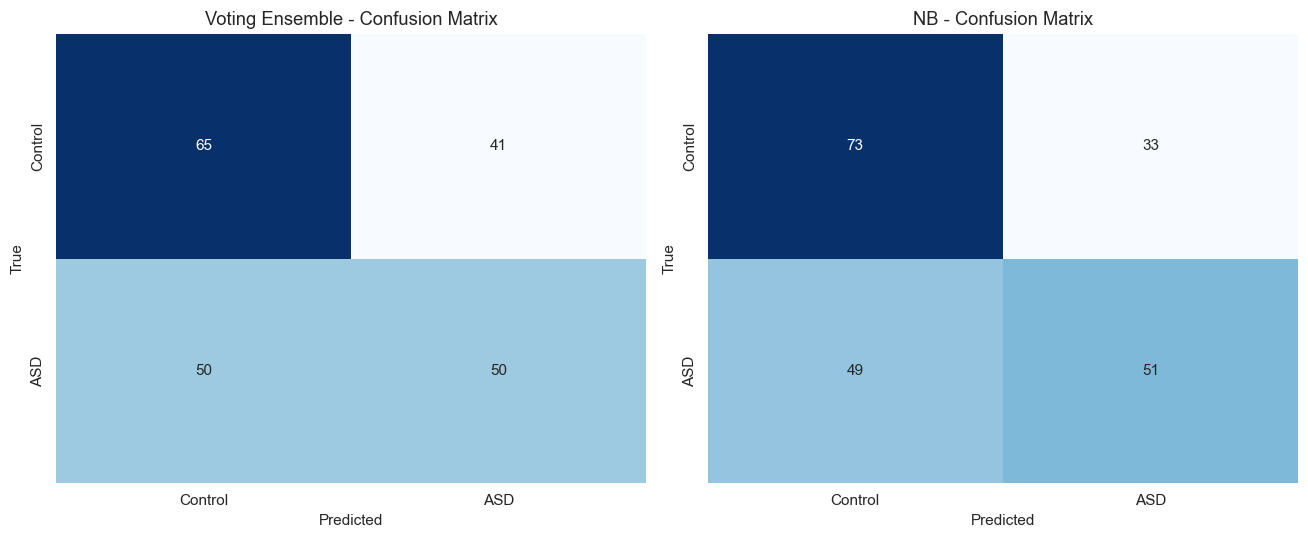

In [13]:
# Confusion Matrices for best models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_models = final_df.sort_values('auc_roc', ascending=False).index[:2]

for i, name in enumerate(top_models):
    y_pred = best_models[name].predict(X_test_pca)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], xticklabels=['Control', 'ASD'], yticklabels=['Control', 'ASD'], cbar=False)
    axes[i].set_title(f'{name} - Confusion Matrix')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')

plt.tight_layout()
plt.show()